# Damond - Local vs. global decay of Moran's I across all genes

`3_moran_scale` summarizes each Moran curve I(k) by its area under the curve (AUC). The AUC is high for genes that
are strongly autocorrelated at *all* scales, so it mixes two things: how strongly a gene is spatially structured
overall, and how quickly that structure disappears with scale. A small ΔI can simply mean that a gene has little
autocorrelation to lose.

Here the decay is split at a user-defined scale `K_SPLIT` into

- **ΔI local** = I(k_min) − I(K_SPLIT): structure lost within small neighborhoods,
- **ΔI global** = I(K_SPLIT) − I(k_max): structure lost at tissue scale.

The two ranges span different numbers of k (e.g. 4 → 16 vs. 16 → 128), so they are compared as
**ΔI per doubling of k** (slope on a log2 k axis) and as **relative** loss (ΔI / I at the start of the range),
which does not depend on the overall autocorrelation level of the gene.

Moran's I is computed per section and averaged over the sections of `CONDITION`.

In [75]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yaml
from scipy.stats import spearmanr

import matplotlib.pyplot as plt

import scanpy as sc

ROOT = Path.cwd()
while not (ROOT / "src" / "moran_scale.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run this notebook from inside the InterScale_reproducibility repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.moran_scale import moran_auc, moran_delta, moran_profile, radii_from_knn  # noqa: E402

## Configuration

In [77]:
DATA = "damond19"
HPC_IMC_PANCREAS = '/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/data/imc_pancreas_pp.h5ad'

with open(ROOT / "figures" / "config.yml") as f:
    config = yaml.safe_load(f)
PLOT_CFG = config["plot_configs"]["general"]
CMAP = config["palettes"]["continuous"]
COLOR_OTHER = "#BBBBBB"
plt.rcParams.update({"font.family": PLOT_CFG["font_family"], "figure.dpi": PLOT_CFG["dpi"]})

LAYER = "pct-norm-99"  # layer to use for Moran's I calculations
LIBRARY_KEY = "ImageNumber"
CONDITION = "Onset"
KS = (4, 8, 16, 32, 64, 128)
K_SPLIT = 16  # k <= K_SPLIT: local, k >= K_SPLIT: global
GRAPH = "knn"  # "knn" or "radius" (radii matched to KS)
MIN_I = 0.1  # genes with mean Moran's I below this at k_min have no structure to lose; shown in grey
N_TOP = 8  # genes labelled / shown per category

FIG_DIR = ROOT / "figures" / DATA / "moran_local_global" / GRAPH
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Moran's I for all genes, per section

In [80]:
adata = sc.read_h5ad(HPC_IMC_PANCREAS)
adata_cond = adata[adata.obs["stage"] == CONDITION].copy()
print(adata_cond.obs[LIBRARY_KEY].value_counts())

if GRAPH == "knn":
    SCALE_COL, SCALES, XLABEL = "k", list(KS), "Number of neighbors (k)"
else:
    SCALE_COL, XLABEL = "radius", "Radius (coordinate units, px)"
    SCALES = list(radii_from_knn(adata, ks=KS, library_key=LIBRARY_KEY))
SPLIT = SCALES[list(KS).index(K_SPLIT)]

prof_sec = moran_profile(
    adata_cond, ks=KS, graph=GRAPH, radii=SCALES if GRAPH == "radius" else None,
    library_key=LIBRARY_KEY, layer=LAYER, per_library=True,
)
#prof_sec.to_csv(FIG_DIR / f"moran_profile_{CONDITION}_per_section.csv", index=False)

# mean Moran curve over sections (genes not expressed in a section are NaN there and skipped)
prof = prof_sec.groupby(["feature", SCALE_COL], as_index=False)["I"].mean()
I = prof.pivot(index="feature", columns=SCALE_COL, values="I")[SCALES]
print(f"{I.shape[0]} genes, {prof_sec['library'].nunique()} {CONDITION} sections")

ImageNumber
215    7302
4      7147
49     7085
211    6776
213    5963
       ... 
669     781
264     771
273     766
274     764
272     618
Name: count, Length: 290, dtype: int64
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO 

## Summary statistics per gene

In [ ]:
stats = moran_delta(prof, split=SPLIT).merge(moran_auc(prof), on="feature")
# positive: the gene loses its autocorrelation mainly within small neighborhoods (local pattern)
stats["local_index"] = stats["slope_local"] - stats["slope_global"]
stats["structured"] = stats["I_min"] >= MIN_I
stats = stats.sort_values("auc", ascending=False).reset_index(drop=True)
stats.to_csv(FIG_DIR / f"moran_local_global_{CONDITION}_split{K_SPLIT}.csv", index=False)
print(f"{stats['structured'].sum()} / {len(stats)} genes with mean I(k_min) >= {MIN_I}")
display(stats.round(3).head(10))

## 1. Highest and lowest AUC

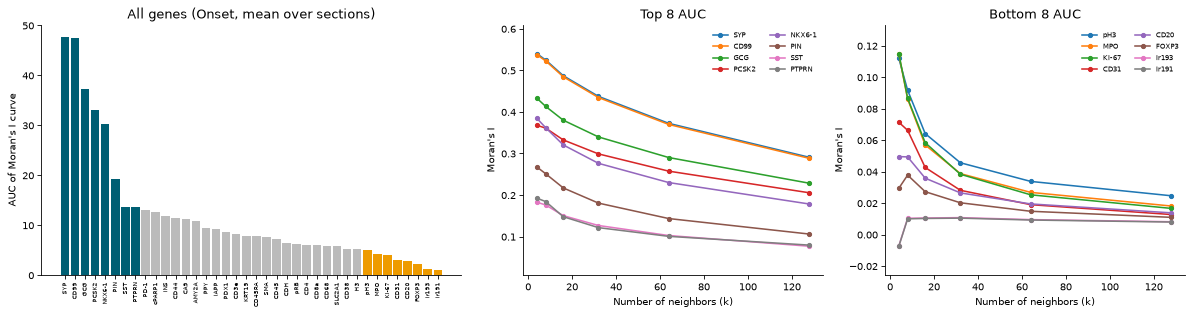

In [81]:
def label_points(ax, x, y, labels, fontsize=7, **kw):
    for xi, yi, lab in zip(x, y, labels):
        ax.annotate(lab, (xi, yi), xytext=(3, 3), textcoords="offset points", fontsize=fontsize, **kw)


top_auc = stats.head(N_TOP)["feature"].tolist()
low_auc = stats.tail(N_TOP)["feature"].tolist()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.4, 1, 1]})
ax = axes[0]
ranked = stats.sort_values("auc", ascending=False).reset_index(drop=True)
colors = [COLOR_GLOBAL if g in top_auc else COLOR_LOCAL if g in low_auc else COLOR_OTHER for g in ranked["feature"]]
ax.bar(range(len(ranked)), ranked["auc"], color=colors, width=0.85)
ax.set_xticks(range(len(ranked)), ranked["feature"], rotation=90, fontsize=6)
ax.set_ylabel("AUC of Moran's I curve")
ax.set_title(f"All genes ({CONDITION}, mean over sections)")
for ax, genes, title in [(axes[1], top_auc, f"Top {N_TOP} AUC"), (axes[2], low_auc, f"Bottom {N_TOP} AUC")]:
    for g, c in zip(genes, plt.get_cmap("tab10").colors):
        ax.plot(SCALES, I.loc[g], marker="o", ms=4, color=c, label=g)
    ax.set_title(title)
    ax.set_xlabel(XLABEL)
    ax.margins(y=0.15)
    ax.legend(frameon=False, fontsize=7, ncol=2, loc="best")
    ax.set_ylabel("Moran's I")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
#plt.savefig(FIG_DIR / "auc_ranking.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

## 2. Is the AUC mostly a measure of overall autocorrelation?

If the AUC is almost fully determined by Moran's I at the smallest scale, it says little about *how* a gene's
structure changes with scale. The right panel shows that the total ΔI does not separate genes the same way.

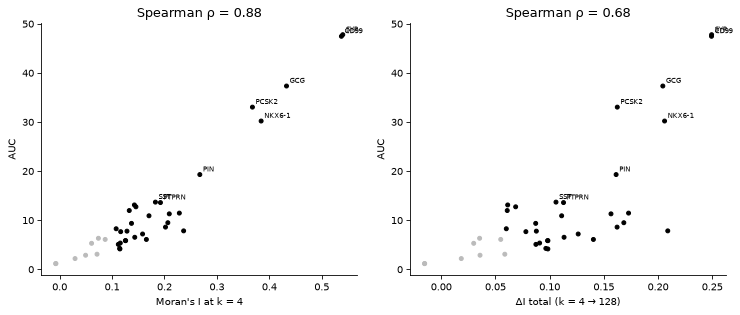

Spearman I(k_min) vs ΔI total: 0.93  (strongly structured genes also have more to lose)


In [82]:
rho_auc_imin = spearmanr(stats["auc"], stats["I_min"]).statistic
rho_auc_dtot = spearmanr(stats["auc"], stats["delta_total"]).statistic
rho_imin_dtot = spearmanr(stats["I_min"], stats["delta_total"]).statistic

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, x, xlab, rho in [
    (axes[0], "I_min", f"Moran's I at k = {KS[0]}", rho_auc_imin),
    (axes[1], "delta_total", f"ΔI total (k = {KS[0]} → {KS[-1]})", rho_auc_dtot),
]:
    ax.scatter(stats[x], stats["auc"], s=14, c=np.where(stats["structured"], "k", COLOR_OTHER))
    label_points(ax, stats.loc[stats["feature"].isin(top_auc), x], stats.loc[stats["feature"].isin(top_auc), "auc"],
                 stats.loc[stats["feature"].isin(top_auc), "feature"])
    ax.set_xlabel(xlab)
    ax.set_ylabel("AUC")
    ax.set_title(f"Spearman ρ = {rho:.2f}")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "auc_vs_baseline.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()
print(f"Spearman I(k_min) vs ΔI total: {rho_imin_dtot:.2f}  (strongly structured genes also have more to lose)")

## 3. Local vs. global decay

Left: absolute decay, ΔI per doubling of k. Right: relative decay, fraction of the autocorrelation lost in each
range. Points above the diagonal lose more structure within small neighborhoods than at tissue scale.
Grey: genes with mean I(k_min) < `MIN_I` (left only; their relative ΔI is undefined).

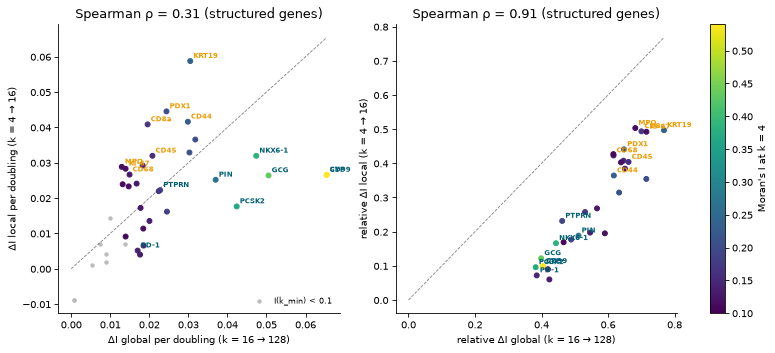

In [83]:
s = stats[stats["structured"]]
top_local = s.sort_values("local_index", ascending=False).head(N_TOP)["feature"].tolist()
top_global_loss = s.sort_values("slope_global", ascending=False).head(N_TOP)["feature"].tolist()
# persistent: strongly structured, and little of it is lost at large scales
persistent = s.sort_values("I_max", ascending=False).head(N_TOP)["feature"].tolist()

rho_abs = spearmanr(s["slope_local"], s["slope_global"]).statistic
rho_rel = spearmanr(s["rel_local"], s["rel_global"]).statistic

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
for ax, (x, y, xlab, ylab, rho) in zip(axes, [
    ("slope_global", "slope_local", f"ΔI global per doubling (k = {K_SPLIT} → {KS[-1]})",
     f"ΔI local per doubling (k = {KS[0]} → {K_SPLIT})", rho_abs),
    ("rel_global", "rel_local", f"relative ΔI global (k = {K_SPLIT} → {KS[-1]})",
     f"relative ΔI local (k = {KS[0]} → {K_SPLIT})", rho_rel),
]):
    if x == "slope_global":  # relative ΔI is undefined for genes without autocorrelation -> absolute panel only
        ns = stats[~stats["structured"]]
        ax.scatter(ns[x], ns[y], s=10, color=COLOR_OTHER, label=f"I(k_min) < {MIN_I}")
    sca = ax.scatter(s[x], s[y], s=22, c=s["I_min"], cmap=CMAP, vmin=MIN_I, zorder=3)
    lim = [min(s[x].min(), s[y].min(), 0), max(s[x].max(), s[y].max())]
    ax.plot(lim, lim, ls="--", lw=0.8, color="grey")
    for genes, c in [(top_local, COLOR_LOCAL), (persistent, COLOR_GLOBAL)]:
        sub = s[s["feature"].isin(genes)]
        label_points(ax, sub[x], sub[y], sub["feature"], color=c, fontweight="bold")
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)
    ax.set_title(f"Spearman ρ = {rho:.2f} (structured genes)")
    ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(sca, ax=axes, label=f"Moran's I at k = {KS[0]}", fraction=0.025)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.savefig(FIG_DIR / f"delta_local_vs_global_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

## 4. Gene rankings

- **local index** = ΔI local − ΔI global (per doubling): genes losing their structure mainly at small scales.
- **ΔI global** (per doubling): genes losing structure at tissue scale.
- **I(k_max)**: genes that keep their autocorrelation up to the largest neighborhood (persistent / global).

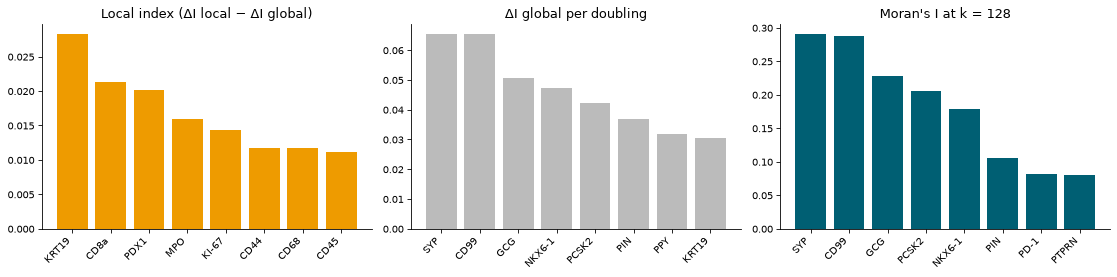

,top local index,top ΔI global,most persistent
0,KRT19,SYP,SYP
1,CD8a,CD99,CD99
2,PDX1,GCG,GCG
3,MPO,NKX6-1,PCSK2
4,KI-67,PCSK2,NKX6-1
5,CD44,PIN,PIN
6,CD68,PPY,PD-1
7,CD45,KRT19,PTPRN


In [84]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, col, genes, color, title in [
    (axes[0], "local_index", top_local, COLOR_LOCAL, "Local index (ΔI local − ΔI global)"),
    (axes[1], "slope_global", top_global_loss, COLOR_OTHER, "ΔI global per doubling"),
    (axes[2], "I_max", persistent, COLOR_GLOBAL, f"Moran's I at k = {KS[-1]}"),
]:
    v = s.set_index("feature").loc[genes, col]
    ax.bar(v.index, v.values, color=color)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"gene_rankings_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

display(pd.DataFrame({"top local index": top_local, "top ΔI global": top_global_loss, "most persistent": persistent}))

## 5. Moran curves and spatial patterns: most local vs. most persistent genes

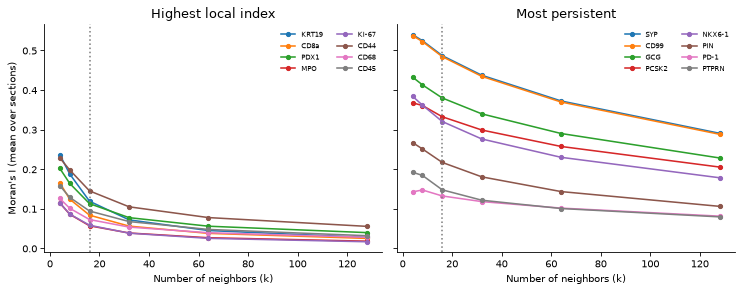

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, genes, title in [(axes[0], top_local, "Highest local index"), (axes[1], persistent, "Most persistent")]:
    for g, c in zip(genes, plt.get_cmap("tab10").colors):
        ax.plot(SCALES, I.loc[g], marker="o", ms=4, color=c, label=g)
    ax.axvline(SPLIT, ls=":", color="grey")
    ax.set_title(title)
    ax.set_xlabel(XLABEL)
    ax.legend(frameon=False, fontsize=7, ncol=2)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Moran's I (mean over sections)")
plt.tight_layout()
plt.savefig(FIG_DIR / f"curves_local_vs_persistent_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

In [90]:
adata

AnnData object with n_obs × n_vars = 1776974 × 38
    obs: 'ImageNumber', 'ObjectNumber', 'Location_Center_X', 'Location_Center_Y', 'Number_Object_Number', 'image_name', 'id', 'CellCat', 'CellType', 'case', 'slide', 'part', 'group', 'stage', 'duration', 'Aab status', 'Age', 'Gender', 'Ethnicity', 'BMI', 'sliding_window_assignment', 'ImageNumber_int', 'split', '_scvi_batch', '_scvi_labels', 'scvi'
    uns: 'CellCat_colors', 'CellType_colors', '_scvi_manager_uuid', '_scvi_uuid', 'morphology', 'scvi'
    obsm: 'X_scVI', 'spatial'
    obsp: 'scvi_connectivities', 'scvi_distances', 'spatial_connectivities', 'spatial_distances'
    layers: 'MeanIntensity', 'MedianIntensity', 'pct-norm-99', 'pct-norm-99_z', None (.X)

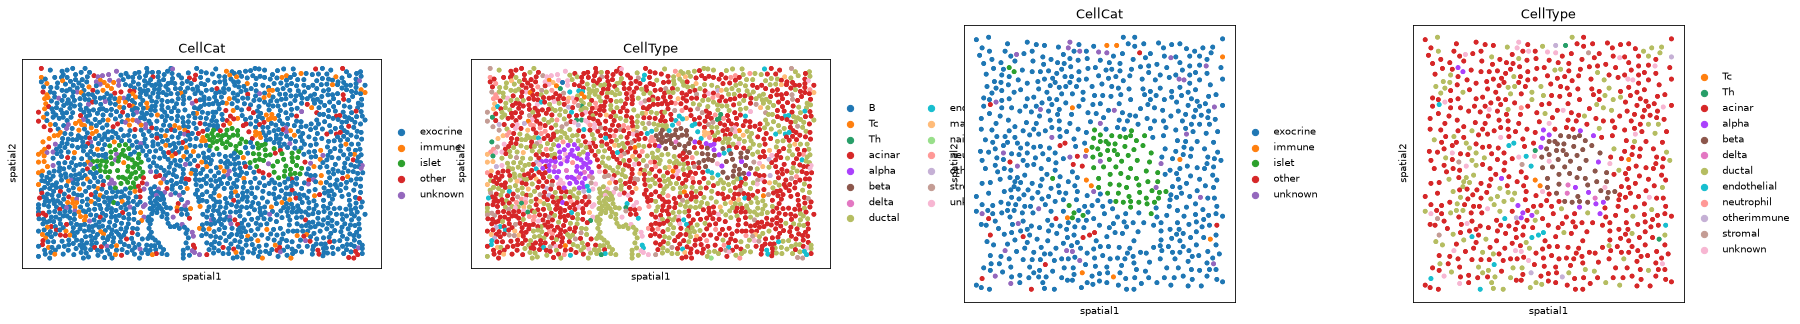

In [95]:
SLIDE = list(np.random.choice(np.unique(adata_cond.obs[LIBRARY_KEY]), 2))
sq.pl.spatial_scatter(
        adata_cond,
        color = ['CellCat','CellType'],
        spatial_key = 'spatial',
        library_key='ImageNumber',
        library_id=SLIDE,
        shape= None,
        size=50
)

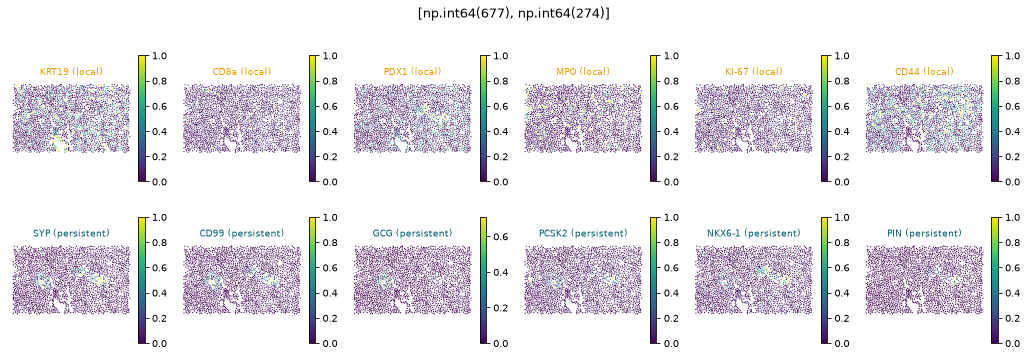

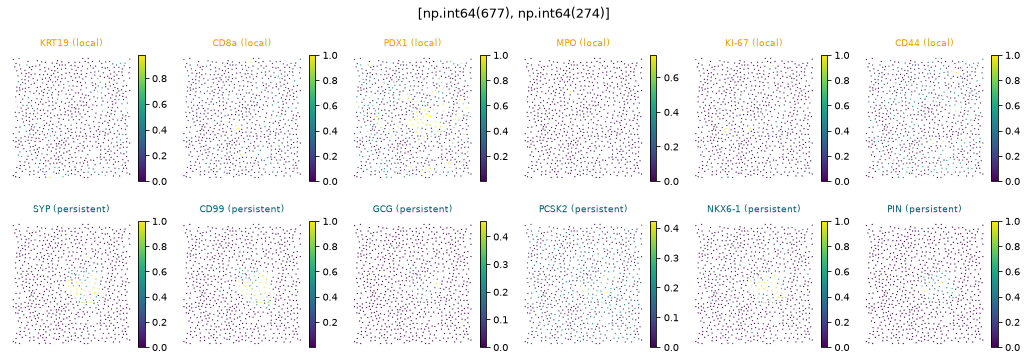

In [98]:
for i in range(len(SLIDE)):
    adata_slide = adata[adata.obs[LIBRARY_KEY] == SLIDE[i]]
    coords = adata_slide.obsm["spatial"]
    n = min(N_TOP, 6)
    fig, axes = plt.subplots(2, n, figsize=(2.3 * n, 5))
    for r, (genes, title) in enumerate([(top_local[:n], "local"), (persistent[:n], "persistent")]):
        X = adata_slide[:, genes].layers[LAYER]
        X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
        for j, g in enumerate(genes):
            ax = axes[r, j]
            order = np.argsort(X[:, j])
            sca = ax.scatter(coords[order, 0], coords[order, 1], c=X[order, j], s=1.5, cmap=CMAP, linewidths=0)
            fig.colorbar(sca, ax=ax, fraction=0.046, pad=0.02)
            ax.set_title(f"{g} ({title})", fontsize=9, color=COLOR_LOCAL if r == 0 else COLOR_GLOBAL)
            ax.set_aspect("equal")
            ax.invert_yaxis()
            ax.axis("off")
    plt.suptitle(SLIDE)
    plt.tight_layout()
    #plt.savefig(FIG_DIR / f"spatial_local_vs_persistent_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
    plt.show()

## 6. Sensitivity to the local / global split

Rank agreement (Spearman) of the local index for different choices of `K_SPLIT`.

In [ ]:
splits = [k for k in KS[1:-1]]
li = pd.DataFrame({
    k: moran_delta(prof, split=SCALES[list(KS).index(k)]).set_index("feature")
    .pipe(lambda d: d["slope_local"] - d["slope_global"]).loc[s["feature"]]
    for k in splits
})
display(li.corr(method="spearman").round(2))
top_by_split = {k: li[k].sort_values(ascending=False).head(N_TOP).index.tolist() for k in splits}
display(pd.DataFrame(top_by_split))